<a href="https://colab.research.google.com/github/steffanymarcellia046/ProjectETSMachineLearning/blob/main/MODEL_QRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install prophet openpyxl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import pandas as pd

# Membaca dataset Coffee Shop Sales
path = '/content/Coffee Shop Sales.xlsx'
try:
    df = pd.read_excel(path, engine='openpyxl')
    print("Dataset berhasil dibaca!")
    print(f"Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
    display(df.head())
except Exception as e:
    print(f"Gagal membaca file Excel: {e}")

Dataset berhasil dibaca!
Ukuran dataset: 149116 baris, 11 kolom


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [3]:
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi data:")
df.info()

print("\nJumlah missing value:")
print(df.isnull().sum())

Ukuran dataset: (149116, 11)

Nama kolom:
['transaction_id', 'transaction_date', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail']

Lima baris pertama:


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg



Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  object        
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  object        
 9   product_type      149116 non-null  object        
 10  product_detail    149116 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(4), object(5)
memory usage: 12.5+ MB

Jumlah missing value:
transaction_id      0
transaction_date    0
transact

Filter data

In [4]:
# Mengubah tanggal ke format datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"],
    errors="coerce"
)

# Mengubah kuantitas menjadi numerik
df["transaction_qty"] = pd.to_numeric(
    df["transaction_qty"],
    errors="coerce"
)

# Menghapus baris yang tanggal atau kuantitasnya tidak valid
df = df.dropna(
    subset=["transaction_date", "transaction_qty", "store_location"]
)

# Memastikan kuantitas tidak negatif
df = df[df["transaction_qty"] >= 0]

# Memilih satu lokasi
df_lokasi = df[
    df["store_location"] == "Hell's Kitchen"
].copy()

print("Jumlah baris setelah filter:", len(df_lokasi))
print("Tanggal awal:", df_lokasi["transaction_date"].min())
print("Tanggal akhir:", df_lokasi["transaction_date"].max())

display(df_lokasi.head())

Jumlah baris setelah filter: 50735
Tanggal awal: 2023-01-01 00:00:00
Tanggal akhir: 2023-06-30 00:00:00


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
17,18,2023-01-01,08:00:18,1,8,Hell's Kitchen,42,2.50,Tea,Brewed herbal tea,Lemon Grass Rg
18,19,2023-01-01,08:00:39,2,8,Hell's Kitchen,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
19,20,2023-01-01,08:11:45,1,8,Hell's Kitchen,61,4.75,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Lg
20,21,2023-01-01,08:17:27,2,8,Hell's Kitchen,33,3.50,Coffee,Gourmet brewed coffee,Ethiopia Lg
23,24,2023-01-01,08:29:38,1,8,Hell's Kitchen,56,2.55,Tea,Brewed Chai tea,Spicy Eye Opener Chai Rg


Penjualan per hari

In [5]:
# Menjumlahkan kuantitas penjualan setiap hari
data_harian = (
    df_lokasi
    .groupby("transaction_date")["transaction_qty"]
    .sum()
    .reset_index()
)

# Menyesuaikan nama kolom untuk Prophet
data_harian = data_harian.rename(
    columns={
        "transaction_date": "ds",
        "transaction_qty": "y"
    }
)

# Membuat rentang tanggal harian yang lengkap
rentang_tanggal = pd.date_range(
    start=data_harian["ds"].min(),
    end=data_harian["ds"].max(),
    freq="D"
)

data_harian = (
    data_harian
    .set_index("ds")
    .reindex(rentang_tanggal, fill_value=0)
    .rename_axis("ds")
    .reset_index()
)

print("Jumlah data harian:", len(data_harian))
print("\nData harian:")
display(data_harian.head(10))

print("\nStatistik deskriptif:")
display(data_harian["y"].describe())

Jumlah data harian: 181

Data harian:


,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235
5,2023-01-06,256
6,2023-01-07,323
7,2023-01-08,277
8,2023-01-09,272
9,2023-01-10,273



Statistik deskriptif:


,y
count,181.000000
mean,396.337017
std,129.535462
min,195.000000
25%,290.000000
50%,363.000000
75%,483.000000
max,769.000000


EDA

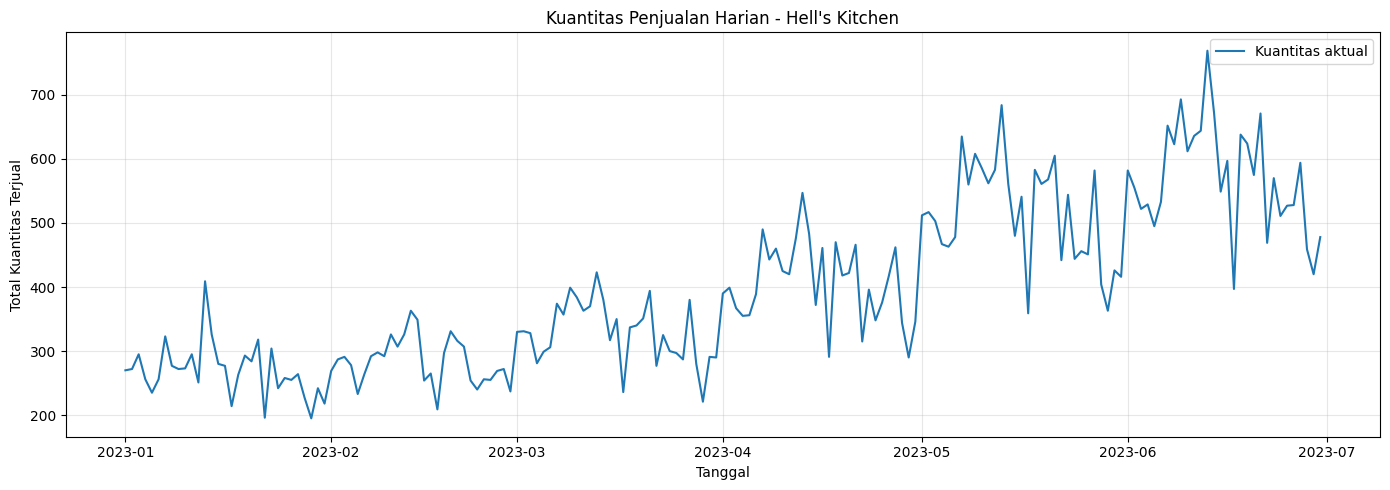

In [6]:
plt.figure(figsize=(14, 5))

plt.plot(
    data_harian["ds"],
    data_harian["y"],
    label="Kuantitas aktual"
)

plt.title("Kuantitas Penjualan Harian - Hell's Kitchen")
plt.xlabel("Tanggal")
plt.ylabel("Total Kuantitas Terjual")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Pola penjuala berdasarkan hari

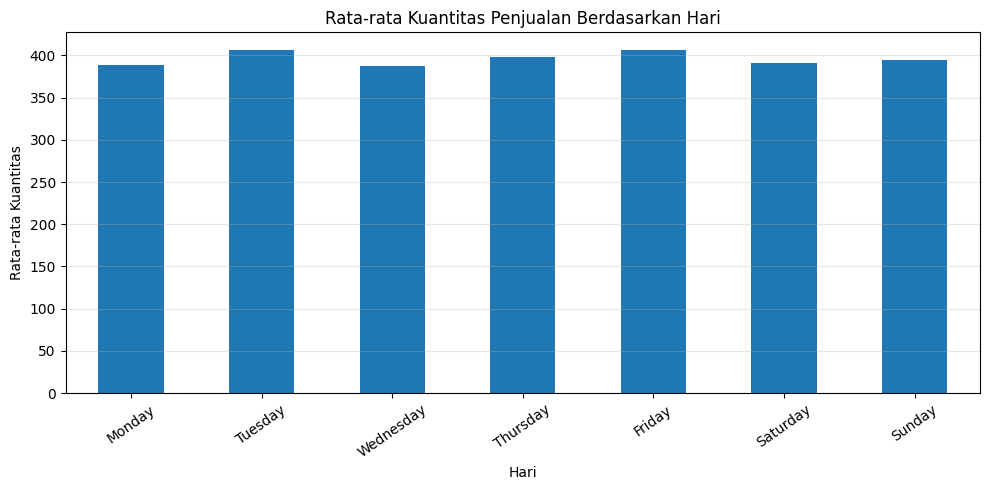

In [7]:
data_harian["nama_hari"] = (
    data_harian["ds"].dt.day_name()
)

urutan_hari = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

rata_hari = (
    data_harian
    .groupby("nama_hari")["y"]
    .mean()
    .reindex(urutan_hari)
)

plt.figure(figsize=(10, 5))
rata_hari.plot(kind="bar")

plt.title("Rata-rata Kuantitas Penjualan Berdasarkan Hari")
plt.xlabel("Hari")
plt.ylabel("Rata-rata Kuantitas")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Pemisahan data training dan testing

In [8]:
# Pastikan urutan tanggal sudah benar
data_harian = data_harian.sort_values("ds").reset_index(drop=True)

# Pembagian berdasarkan waktu
split_index = int(len(data_harian) * 0.80)

train = data_harian.iloc[:split_index][["ds", "y"]].copy()
test = data_harian.iloc[split_index:][["ds", "y"]].copy()

print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))

print("\nPeriode training:")
print(train["ds"].min(), "sampai", train["ds"].max())

print("\nPeriode testing:")
print(test["ds"].min(), "sampai", test["ds"].max())

Jumlah data training: 144
Jumlah data testing: 37

Periode training:
2023-01-01 00:00:00 sampai 2023-05-24 00:00:00

Periode testing:
2023-05-25 00:00:00 sampai 2023-06-30 00:00:00


Model QRF

In [9]:
!pip install -q quantile-forest
from quantile_forest import RandomForestQuantileRegressor

In [10]:
df_model = data_harian.copy()
df_model

,ds,y,nama_hari
0,2023-01-01,270,Sunday
1,2023-01-02,272,Monday
2,2023-01-03,295,Tuesday
3,2023-01-04,256,Wednesday
4,2023-01-05,235,Thursday
...,...,...,...
176,2023-06-26,528,Monday
177,2023-06-27,594,Tuesday
178,2023-06-28,459,Wednesday
179,2023-06-29,420,Thursday


Fitur Calendar

In [11]:
df_model['day_of_week'] = df_model['ds'].dt.dayofweek
df_model['day_of_month'] = df_model['ds'].dt.day
df_model['month'] = df_model['ds'].dt.month
df_model['is_weekend'] = df_model['day_of_week'].isin([5, 6]).astype(int)

In [12]:

df_model

,ds,y,nama_hari,day_of_week,day_of_month,month,is_weekend
0,2023-01-01,270,Sunday,6,1,1,1
1,2023-01-02,272,Monday,0,2,1,0
2,2023-01-03,295,Tuesday,1,3,1,0
3,2023-01-04,256,Wednesday,2,4,1,0
4,2023-01-05,235,Thursday,3,5,1,0
...,...,...,...,...,...,...,...
176,2023-06-26,528,Monday,0,26,6,0
177,2023-06-27,594,Tuesday,1,27,6,0
178,2023-06-28,459,Wednesday,2,28,6,0
179,2023-06-29,420,Thursday,3,29,6,0


Fitur Lag 1, 7, 14 (Pola harian dan mingguan)

In [13]:
for lag in [1, 2, 3, 7, 14]:
    df_model[f'lag_{lag}'] = df_model['y'].shift(lag)

In [14]:
df_model

,ds,y,nama_hari,day_of_week,day_of_month,month,is_weekend,lag_1,lag_2,lag_3,lag_7,lag_14
0,2023-01-01,270,Sunday,6,1,1,1,NaN,NaN,NaN,NaN,NaN
1,2023-01-02,272,Monday,0,2,1,0,270.0,NaN,NaN,NaN,NaN
2,2023-01-03,295,Tuesday,1,3,1,0,272.0,270.0,NaN,NaN,NaN
3,2023-01-04,256,Wednesday,2,4,1,0,295.0,272.0,270.0,NaN,NaN
4,2023-01-05,235,Thursday,3,5,1,0,256.0,295.0,272.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
176,2023-06-26,528,Monday,0,26,6,0,527.0,511.0,570.0,624.0,644.0
177,2023-06-27,594,Tuesday,1,27,6,0,528.0,527.0,511.0,575.0,769.0
178,2023-06-28,459,Wednesday,2,28,6,0,594.0,528.0,527.0,671.0,672.0
179,2023-06-29,420,Thursday,3,29,6,0,459.0,594.0,528.0,469.0,549.0


Rolling Features (mean 7 hari)

In [15]:
df_model['rolling_mean_7'] = df_model['y'].shift(1).rolling(window=7).mean()
df_model['rolling_std_7'] = df_model['y'].shift(1).rolling(window=7).std()

In [16]:
df_model

,ds,y,nama_hari,day_of_week,day_of_month,month,is_weekend,lag_1,lag_2,lag_3,lag_7,lag_14,rolling_mean_7,rolling_std_7
0,2023-01-01,270,Sunday,6,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-02,272,Monday,0,2,1,0,270.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2023-01-03,295,Tuesday,1,3,1,0,272.0,270.0,NaN,NaN,NaN,NaN,NaN
3,2023-01-04,256,Wednesday,2,4,1,0,295.0,272.0,270.0,NaN,NaN,NaN,NaN
4,2023-01-05,235,Thursday,3,5,1,0,256.0,295.0,272.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176,2023-06-26,528,Monday,0,26,6,0,527.0,511.0,570.0,624.0,644.0,563.857143,68.809952
177,2023-06-27,594,Tuesday,1,27,6,0,528.0,527.0,511.0,575.0,769.0,550.142857,64.240248
178,2023-06-28,459,Wednesday,2,28,6,0,594.0,528.0,527.0,671.0,672.0,552.857143,65.846864
179,2023-06-29,420,Thursday,3,29,6,0,459.0,594.0,528.0,469.0,549.0,522.571429,49.067495


Hapus Missing Value (Lag dan Rolling)

In [17]:
df_model = df_model.dropna().reset_index(drop=True)

In [18]:
print("Ukuran dataset setelah feature engineering:", df_model.shape)
display(df_model.head())

Ukuran dataset setelah feature engineering: (167, 14)


,ds,y,nama_hari,day_of_week,day_of_month,month,is_weekend,lag_1,lag_2,lag_3,lag_7,lag_14,rolling_mean_7,rolling_std_7
0,2023-01-15,280,Sunday,6,15,1,1,326.0,409.0,251.0,277.0,270.0,300.428571,53.266178
1,2023-01-16,277,Monday,0,16,1,0,280.0,326.0,409.0,272.0,272.0,300.857143,53.057920
2,2023-01-17,214,Tuesday,1,17,1,0,277.0,280.0,326.0,273.0,295.0,301.571429,52.636670
3,2023-01-18,263,Wednesday,2,18,1,0,214.0,277.0,280.0,295.0,256.0,293.142857,61.885455
4,2023-01-19,293,Thursday,3,19,1,0,263.0,214.0,277.0,251.0,235.0,288.571429,62.899012


Split

In [28]:
import pandas as pd

# ==========================================
# 1. SPLIT DATA KRONOLOGIS (70% Train, 15% Val, 15% Test)
# ==========================================
feature_cols = [
    'day_of_week',
    'day_of_month',
    'month',
    'is_weekend',
    'lag_1',
    'lag_2',
    'lag_3',
    'lag_7',
    'lag_14',
    'rolling_mean_7',
    'rolling_std_7',
]

X = df_model[feature_cols]
y = df_model['y']
dates = df_model['ds']

total_len = len(df_model)

# Tentukan batas indeks persentase baru
train_end = int(total_len * 0.80)
val_end = int(total_len * 0.90)

# 1. Data Training (Untuk melatih model awal saat tuning Optuna)
X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]

# 2. Data Validasi (Digunakan Optuna untuk mencari parameter terbaik)
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]

# 3. Data Testing / Uji Murni (Disembunyikan sepenuhnya untuk evaluasi akhir)
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]
dates_test = dates.iloc[val_end:]

print(f'Total Data     : {total_len} hari')
print(f'Data Latih     : {len(X_train)} hari (70%)')
print(f'Data Validasi  : {len(X_val)} hari (15% - untuk Optuna)')
print(f'Data Uji (Test): {len(X_test)} hari (15% - untuk Evaluasi Akhir)')

Total Data     : 167 hari
Data Latih     : 133 hari (70%)
Data Validasi  : 17 hari (15% - untuk Optuna)
Data Uji (Test): 17 hari (15% - untuk Evaluasi Akhir)


Tuning Optuna

In [20]:
!pip install -q optuna quantile-forest
import optuna
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [40]:
import numpy as np
import pandas as pd
from quantile_forest import RandomForestQuantileRegressor
import optuna
from sklearn.metrics import mean_absolute_error

# Matikan log verbose optuna yang berlebihan
optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial):
  # 1. Ruang pencarian hiperparameter
  params = {
      'n_estimators': trial.suggest_int('n_estimators', 50, 300, step=50),
      'max_depth': trial.suggest_int('max_depth', 5, 30, step=5),
      'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
      'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
      'max_features': trial.suggest_categorical(
          'max_features', ['sqrt', 'log2', 1.0, None]
      ),
  }

  # 2. Inisialisasi model
  model = RandomForestQuantileRegressor(
      **params, random_state=42, n_jobs=-1
  )

  # 3. Latih model menggunakan Data Training
  model.fit(X_train, y_train)

  # 4. Prediksi pada Data Validasi (X_val) untuk tuning Optuna
  preds = model.predict(X_val, quantiles=[0.05, 0.50, 0.95])
  y_pred_lower = preds[:, 0]
  y_pred_median = preds[:, 1]
  y_pred_upper = preds[:, 2]

  # 5. Evaluasi Metrik pada Validasi: MAE & PICP
  mae = mean_absolute_error(y_val, y_pred_median)

  in_interval = (y_val.values >= y_pred_lower) & (
      y_val.values <= y_pred_upper
  )
  picp = np.mean(in_interval)

  # 6. Fungsi Objektif Gabungan (Custom Loss dengan penalti PICP yang ditingkatkan)
  picp_target = 0.90
  penalty = (
      abs(picp - picp_target) * 1000
  )  # Diperkuat agar Optuna fokus mengejar PICP ~90%
  score = mae + penalty

  return score


# 7. Jalankan Studi Optuna Kembali
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=40, show_progress_bar=True)

# 8. Tampilkan Hasil Parameter Terbaik
print('=== HASIL TUNING OPTUNA TERBAIK ===')
print(f'Score Terbaik (Loss): {study.best_value:.4f}')
print('Parameter Terbaik:')
for key, value in study.best_params.items():
  print(f'  - {key}: {value}')

  0%|          | 0/40 [00:00<?, ?it/s]

=== HASIL TUNING OPTUNA TERBAIK ===
Score Terbaik (Loss): 95.9412
Parameter Terbaik:
  - n_estimators: 50
  - max_depth: 5
  - min_samples_split: 19
  - min_samples_leaf: 1
  - max_features: log2


PEMODELAN

In [41]:

# 1. Masukkan parameter terbaik hasil Optuna secara otomatis menggunakan unpacking (**study.best_params)
best_params = study.best_params

print('=== PARAMETER TERBAIK YANG DIGUNAKAN ===')
for k, v in best_params.items():
  print(f'  {k}: {v}')

# 2. Inisialisasi model baru dengan parameter terbaik
optimized_qrf_model = RandomForestQuantileRegressor(
    **best_params, random_state=42, n_jobs=-1
)

# 3. Latih model pada data training
optimized_qrf_model.fit(X_train, y_train)

# 4. Prediksi Kuantil pada Data Test (0.1, 0.5, 0.9 untuk interval 80%)
preds_optimized = optimized_qrf_model.predict(X_test, quantiles=[0.05, 0.50, 0.95])
y_pred_lower_opt = preds_optimized[:, 0]  # Q10 (Bawah)
y_pred_median_opt = preds_optimized[:, 1]  # Q50 (Median)
y_pred_upper_opt = preds_optimized[:, 2]  # Q90 (Atas)

=== PARAMETER TERBAIK YANG DIGUNAKAN ===
  n_estimators: 50
  max_depth: 5
  min_samples_split: 19
  min_samples_leaf: 1
  max_features: log2


In [42]:
import pandas as pd

# Membuat DataFrame untuk melihat perbandingan batas bawah, median, dan batas atas hasil peramalan QRF
hasil_qrf = pd.DataFrame({
    'Tanggal': dates_test,
    'Batas Bawah (y_pred_lower)': y_pred_lower_opt,
    'Prediksi Utama (y_pred_median)': y_pred_median_opt,
    'Batas Atas (y_pred_upper)': y_pred_upper_opt
})

display(hasil_qrf)

,Tanggal,Batas Bawah (y_pred_lower),Prediksi Utama (y_pred_median),Batas Atas (y_pred_upper)
150,2023-06-14,447.15,561.0,684.00
151,2023-06-15,442.90,561.0,684.00
152,2023-06-16,404.40,554.0,684.00
153,2023-06-17,375.65,552.5,684.00
154,2023-06-18,352.95,544.0,684.00
155,2023-06-19,350.75,529.0,622.85
156,2023-06-20,368.45,544.0,684.00
157,2023-06-21,416.70,561.0,684.00
158,2023-06-22,416.70,561.0,684.00
159,2023-06-23,382.80,545.5,684.00


In [43]:
# 1. Evaluasi Point Forecast
mae_val = mean_absolute_error(y_test, y_pred_median_opt)
rmse_val = np.sqrt(mean_squared_error(y_test, y_pred_median_opt))

# 2. Evaluasi Interval (PICP & MPIW untuk interval 80% / Q10 - Q90)
# PICP: Cek berapa persen data aktual berada di antara lower dan upper
in_interval = (y_test.values >= y_pred_lower_opt) & (y_test.values <= y_pred_upper_opt)
picp = np.mean(in_interval) * 100

# MPIW: Rata-rata lebar interval
mpiw = np.mean(y_pred_upper_opt - y_pred_lower_opt)

print('=== EVALUASI LENGKAP QRF ===')
print(f'MAE  : {mae_val:.2f} transaksi')
print(f'RMSE : {rmse_val:.2f} transaksi')
print(
    f'PICP : {picp:.2f}%'
)
print(f'MPIW : {mpiw:.2f}')

=== EVALUASI LENGKAP QRF ===
MAE  : 66.38 transaksi
RMSE : 79.19 transaksi
PICP : 94.12%
MPIW : 287.78


In [44]:
import numpy as np

# 1. Pastikan y_test dan y_pred_median_opt sudah ada
# y_test: data aktual, y_pred_median_opt: prediksi Q50 dari model QRF optimal

y_true = y_test.values
y_pred = y_pred_median_opt

# 2. Hitung MAPE (Mean Absolute Percentage Error)
# Ditambah epsilon (1e-8) untuk menghindari pembagian dengan nol jika ada nilai aktual 0
mape_qrf = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100

# 3. Hitung sMAPE (Symmetric Mean Absolute Percentage Error)
smape_qrf = (
    np.mean(
        2.0
        * np.abs(y_true - y_pred)
        / (np.abs(y_true) + np.abs(y_pred) + 1e-8)
    )
    * 100
)

print('=== EVALUASI PERSENTASE ERROR QRF (Q50) ===')
print(f'MAPE  : {mape_qrf:.4f}%')
print(f'sMAPE : {smape_qrf:.4f}%')

=== EVALUASI PERSENTASE ERROR QRF (Q50) ===
MAPE  : 12.7775%
sMAPE : 12.3142%


PROPHET + QRF

Hasil Prediksi Prophet (30 hari ke depan):


,ds,yhat,yhat_lower,yhat_upper
181,2023-07-01,480.061385,402.868459,550.084740
182,2023-07-02,507.164711,436.844708,575.200841
183,2023-07-03,523.151321,456.909118,597.956186
184,2023-07-04,570.293818,502.852155,645.222481
185,2023-07-05,587.849868,513.084656,659.288672
186,2023-07-06,642.456890,573.576101,715.405441
187,2023-07-07,702.228164,629.455933,774.393985
188,2023-07-08,747.560116,674.035105,823.015853
189,2023-07-09,822.471929,750.462484,893.890575
190,2023-07-10,883.533683,811.921817,953.203376


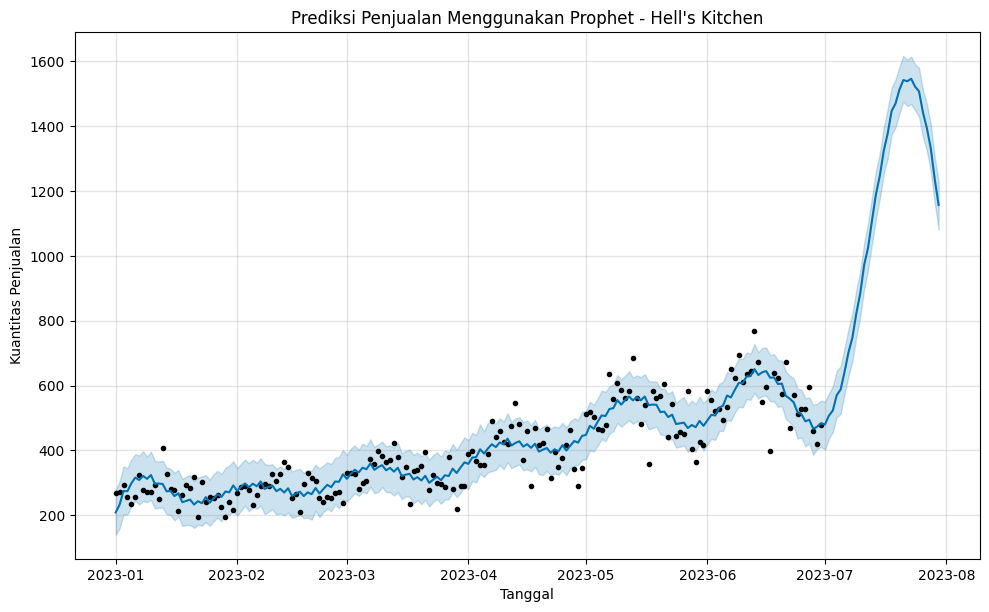

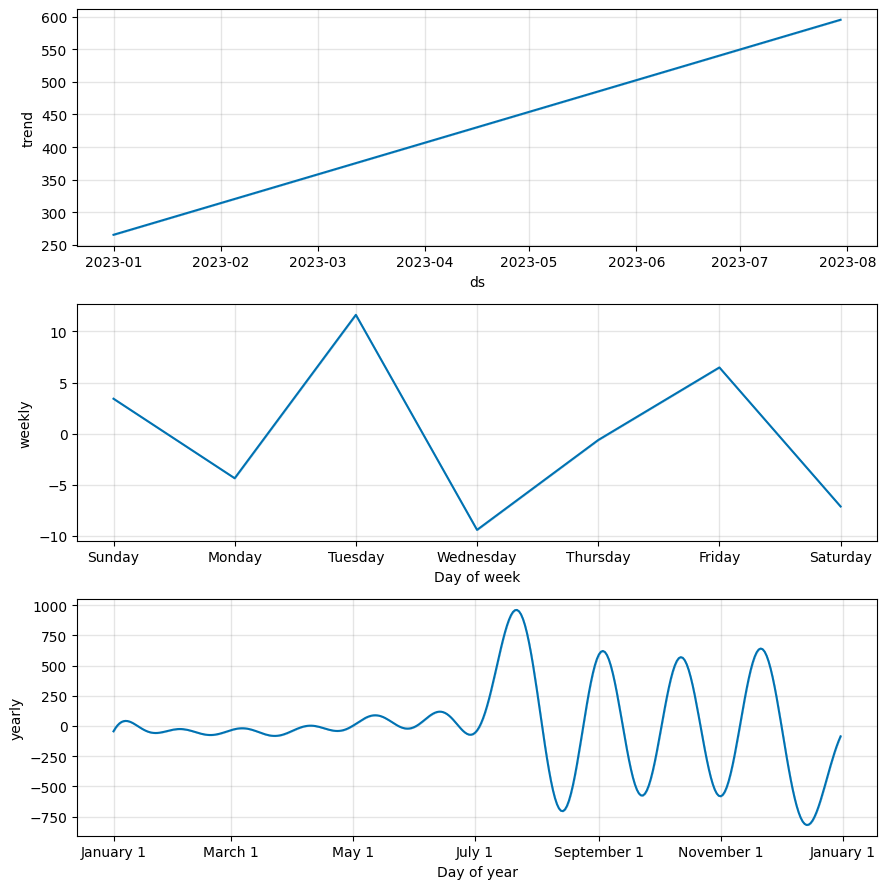

In [45]:
from prophet import Prophet

# 1. Menyiapkan DataFrame untuk Prophet (sudah menggunakan kolom 'ds' dan 'y')
df_prophet = data_harian[['ds', 'y']].copy()

# 2. Inisialisasi dan melatih model Prophet
model_prophet = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)
model_prophet.fit(df_prophet)

# 3. Membuat dataframe masa depan untuk prediksi (misalnya 30 hari ke depan)
future_prophet = model_prophet.make_future_dataframe(periods=30)

# 4. Melakukan prediksi
forecast = model_prophet.predict(future_prophet)

# 5. Menampilkan beberapa hasil prediksi terakhir
print("Hasil Prediksi Prophet (30 hari ke depan):")
display(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(30))

# 6. Visualisasi Hasil Prediksi Prophet
fig1 = model_prophet.plot(forecast)
plt.title("Prediksi Penjualan Menggunakan Prophet - Hell's Kitchen")
plt.xlabel("Tanggal")
plt.ylabel("Kuantitas Penjualan")
plt.show()

# 7. Visualisasi Komponen Prophet (Tren, Mingguan, dll)
fig2 = model_prophet.plot_components(forecast)
plt.show()

In [57]:
import optuna
import numpy as np
import pandas as pd
from prophet import Prophet
from quantile_forest import RandomForestQuantileRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Pastikan data dasar dan Prophet sudah siap
df_model = data_harian.copy()

model_prophet = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False
)
model_prophet.fit(df_model[['ds', 'y']])
forecast_train = model_prophet.predict(df_model[['ds']])
df_model['prophet_pred'] = forecast_train['yhat'].values
df_model['residu'] = df_model['y'] - df_model['prophet_pred']

# 2. Ekstraksi Fitur
df_model['day_of_week'] = pd.to_datetime(df_model['ds']).dt.dayofweek
df_model['month'] = pd.to_datetime(df_model['ds']).dt.month
X = pd.get_dummies(df_model[['nama_hari', 'day_of_week', 'month']], drop_first=True)
y_residu = df_model['residu']
y_actual = df_model['y']

# 3. Definisikan Objective Function untuk Optuna
def objective(trial):
    # Hyperparameter search space untuk QRF
    n_estimators = trial.suggest_int('n_estimators', 50, 200)
    max_depth = trial.suggest_int('max_depth', 3, 20)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 20)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 20)

    # Latih QRF dengan parameter trial
    qrf = RandomForestQuantileRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        random_state=42
    )
    qrf.fit(X, y_residu)

    # Prediksi kuantil (Q10 dan Q90 untuk interval 80%)
    preds = qrf.predict(X, quantiles=[0.10, 0.50, 0.90])
    lower = df_model['prophet_pred'] + preds[:, 0]
    upper = df_model['prophet_pred'] + preds[:, 2]

    # Hitung PICP (Coverage)
    in_interval = (y_actual >= lower) & (y_actual <= upper)
    picp = np.mean(in_interval) * 100.0

    # Hitung MPIW (Lebar Interval)
    mpiw = np.mean(upper - lower)

    # Custom Loss / Penalty untuk Optuna:
    # Kita ingin PICP sedekat mungkin dengan target ideal (80%),
    # sekaligus menekan MPIW agar sekecil mungkin.
    # Jika PICP jauh dari 80%, berikan penalti yang besar.
    target_picp = 80.0
    penalty = abs(picp - target_picp) * 5.0  # Penalti jika melenceng dari 80%

    score = mpiw + penalty
    return score

# 4. Jalankan Study Optuna
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30)

print("=== OPTIMASI OPTUNA SELESAI ===")
print("Hyperparameter terbaik:", study.best_params)

# 5. Latih Ulang Model Final Menggunakan Parameter Terbaik dari Optuna
best_params = study.best_params
best_qrf = RandomForestQuantileRegressor(**best_params, random_state=42)
best_qrf.fit(X, y_residu)

# Evaluasi Akhir dengan Model Terbaik
best_preds = best_qrf.predict(X, quantiles=[0.10, 0.50, 0.90])
df_model['ensemble_pred'] = df_model['prophet_pred'] + best_preds[:, 1]
df_model['ensemble_lower'] = df_model['prophet_pred'] + best_preds[:, 0]
df_model['ensemble_upper'] = df_model['prophet_pred'] + best_preds[:, 2]

final_mae = mean_absolute_error(y_actual, df_model['ensemble_pred'])
final_rmse = np.sqrt(mean_squared_error(y_actual, df_model['ensemble_pred']))
final_picp = np.mean((y_actual >= df_model['ensemble_lower']) & (y_actual <= df_model['ensemble_upper'])) * 100
final_mpiw = np.mean(df_model['ensemble_upper'] - df_model['ensemble_lower'])

print("\n=== HASIL EVALUASI SETELAH OPTIMASI OPTUNA ===")
print(f"MAE  : {final_mae:.4f}")
print(f"RMSE : {final_rmse:.4f}")
print(f"PICP : {final_picp:.2f}% (Target ideal ~80%)")
print(f"MPIW : {final_mpiw:.4f}")

display(df_model[['ds', 'y', 'ensemble_pred', 'ensemble_lower', 'ensemble_upper']].tail())

=== OPTIMASI OPTUNA SELESAI ===
Hyperparameter terbaik: {'n_estimators': 67, 'max_depth': 10, 'min_samples_split': 20, 'min_samples_leaf': 11}

=== HASIL EVALUASI SETELAH OPTIMASI OPTUNA ===
MAE  : 53.2475
RMSE : 71.5558
PICP : 80.66% (Target ideal ~80%)
MPIW : 155.4329


,ds,y,ensemble_pred,ensemble_lower,ensemble_upper
176,2023-06-26,528,619.870456,459.751408,705.274161
177,2023-06-27,594,637.988168,477.869120,723.391873
178,2023-06-28,459,632.317558,458.806636,704.329389
179,2023-06-29,420,646.658779,509.542861,710.299732
180,2023-06-30,478,667.341099,534.668001,706.648104


In [58]:
# 1. Fungsi untuk menghitung MAPE (%)
def calculate_mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Menghindari pembagian dengan angka 0
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

# 2. Fungsi untuk menghitung sMAPE (%)
def calculate_smape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    mask = denominator != 0
    return np.mean(np.abs(y_true[mask] - y_pred[mask]) / denominator[mask]) * 100

# 3. Hitung nilainya berdasarkan hasil ensemble prediksi
y_actual = df_model['y']
y_pred_ensemble = df_model['ensemble_pred']

final_mape = calculate_mape(y_actual, y_pred_ensemble)
final_smape = calculate_smape(y_actual, y_pred_ensemble)

# 4. Tampilkan hasil evaluasi lengkap termasuk MAPE & sMAPE
print("=== EVALUASI LENGKAP POINT FORECAST & INTERVAL ===")
print(f"MAE   : {final_mae:.4f}")
print(f"RMSE  : {final_rmse:.4f}")
print(f"MAPE  : {final_mape:.2f}%")
print(f"sMAPE : {final_smape:.2f}%")
print(f"PICP  : {final_picp:.2f}% (Target ideal ~80%)")
print(f"MPIW  : {final_mpiw:.4f}")

=== EVALUASI LENGKAP POINT FORECAST & INTERVAL ===
MAE   : 53.2475
RMSE  : 71.5558
MAPE  : 14.43%
sMAPE : 13.26%
PICP  : 80.66% (Target ideal ~80%)
MPIW  : 155.4329
